In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
from functools import reduce
from pathlib import Path

In [58]:
# 1. Definir la ruta y los archivos a leer (ordenados del más antiguo al más nuevo)
carpeta = Path.cwd()
archivos_excel = [
    "Totalizadores Planta 2020_2022.xlsx",
    "Totalizadores Planta - 2021_2023.xlsx",
    "Totalizadores Planta 2022_2023.xlsx"
]

# Diccionario para agrupar los datos de todas las horas
datos_por_hoja = {}

# 2. Leer todos los archivos y agrupar sus hojas
for nombre_archivo in archivos_excel:
    ruta_excel = carpeta / nombre_archivo
    print(f"Leyendo archivo: {nombre_archivo}...")
    
    diccionario_hojas = pd.read_excel(ruta_excel, sheet_name=None)
    
    for nombre_hoja, df in diccionario_hojas.items():
        if 'DIA' not in df.columns or 'HORA' not in df.columns:
            continue

        # 1. Normalizar la fecha
        df['DIA'] = pd.to_datetime(df['DIA'], errors='coerce').dt.normalize()

        # 2. VERIFICACIÓN DE JORNADAS APILADAS (> 25 registros)
        conteo_dias = df.groupby('DIA').size()
        dias_corruptos = conteo_dias[conteo_dias > 25]

        if not dias_corruptos.empty:
            print(f"\n🚨 ALERTA en '{nombre_archivo}' - Hoja '{nombre_hoja}':")
            print("Se encontraron fechas con más de 25 registros (jornadas apiladas):")
            for fecha, cantidad in dias_corruptos.items():
                print(f"   - {fecha.strftime('%Y-%m-%d')}: {cantidad} registros")
            
            # Descartar los días corruptos
            df = df[~df['DIA'].isin(dias_corruptos.index)].copy()
            print("   -> 🗑️ Estos días fueron descartados para proteger la integridad del dataset.\n")

        # 3. Limpiar la columna HORA para evitar espacios raros
        df['HORA'] = df['HORA'].astype(str).str.strip()
        
        # 4. Guardar TODO el DataFrame
        if not df.empty:
            if nombre_hoja not in datos_por_hoja:
                datos_por_hoja[nombre_hoja] = []
            datos_por_hoja[nombre_hoja].append(df)


# =============================================================================
# BLOQUE: APILAR AÑOS, RESOLVER DISCREPANCIAS Y RENOMBRAR COLUMNAS
# =============================================================================
dfs_listos_para_cruzar = []
print("\nProcesando y resolviendo discrepancias en fechas/horas solapadas...")

for nombre_hoja, lista_dfs in datos_por_hoja.items():
    # Juntamos todos los dataframes de la misma hoja a lo largo de los distintos archivos
    df_hoja_completa = pd.concat(lista_dfs, ignore_index=True)
    
    # ELIMINAR SOLAPAMIENTO: Mantenemos el último (el del archivo más reciente)
    df_hoja_completa = df_hoja_completa.drop_duplicates(subset=['DIA', 'HORA'], keep='last')
    
    # Renombrar columnas agregando el nombre de la hoja (excepto DIA y HORA)
    columnas_valores = [col for col in df_hoja_completa.columns if col not in ['DIA', 'HORA']]
    renombres = {col: f"{col} ({nombre_hoja})" for col in columnas_valores}
    df_hoja_completa.rename(columns=renombres, inplace=True)
    
    dfs_listos_para_cruzar.append(df_hoja_completa)


# =============================================================================
# BLOQUE: CRUZAR TODAS LAS HOJAS
# =============================================================================
if dfs_listos_para_cruzar:
    print("\nCruzando todas las tablas en una sola...")
    # Hacemos un merge conservando DIA y HORA
    df_final = reduce(lambda left, right: pd.merge(left, right, on=['DIA', 'HORA'], how='outer'), dfs_listos_para_cruzar)
    
    # Ordenamos de forma cronológica por día y hora
    df_final = df_final.sort_values(['DIA', 'HORA']).reset_index(drop=True)
    
    print(f"\n¡Éxito! Procesamiento terminado.")
    print(f"📊 El dataset 'df_final' está listo en memoria con {df_final.shape[0]} filas y {df_final.shape[1]} columnas.\n")

else:
    print("\nNo se encontraron registros válidos para procesar.")
    df_final = pd.DataFrame() # Creamos un df vacío para evitar errores de variable no definida más adelante

Leyendo archivo: Totalizadores Planta 2020_2022.xlsx...

🚨 ALERTA en 'Totalizadores Planta 2020_2022.xlsx' - Hoja 'Consolidado KPI':
Se encontraron fechas con más de 25 registros (jornadas apiladas):
   - 2020-09-30: 50 registros
   - 2020-11-30: 50 registros
   - 2021-02-28: 100 registros
   - 2021-04-30: 50 registros
   - 2021-06-30: 51 registros
   - 2021-09-30: 50 registros
   - 2021-11-30: 50 registros
   - 2022-02-28: 100 registros
   -> 🗑️ Estos días fueron descartados para proteger la integridad del dataset.


🚨 ALERTA en 'Totalizadores Planta 2020_2022.xlsx' - Hoja 'Consolidado Produccion':
Se encontraron fechas con más de 25 registros (jornadas apiladas):
   - 2020-09-30: 50 registros
   - 2020-11-30: 50 registros
   - 2021-02-28: 100 registros
   - 2021-04-30: 50 registros
   - 2021-06-30: 51 registros
   - 2021-09-30: 50 registros
   - 2021-11-30: 50 registros
   - 2022-02-28: 100 registros
   -> 🗑️ Estos días fueron descartados para proteger la integridad del dataset.


🚨 

EL criterio de desempate fue tomar el excel más reciente

Análisis Descriptivo y Versionado Inicial de Datos

ACA tendria que implementar el sistema de checksums

Convertimos las comas en puntos y las columnas a flotantes

In [59]:
df_final.head()

,DIA,HORA,EE Planta / Hl (Consolidado KPI),EE Elaboracion / Hl (Consolidado KPI),EE Bodega / Hl (Consolidado KPI),EE Cocina / Hl (Consolidado KPI),EE Envasado / Hl (Consolidado KPI),EE Linea 2 / Hl (Consolidado KPI),EE Linea 3 / Hl (Consolidado KPI),EE Linea 4 / Hl (Consolidado KPI),...,.28 (Auxiliar),.29 (Auxiliar),.30 (Auxiliar),.31 (Auxiliar),Unnamed: 0 (Auxiliar),Unnamed: 3 (Auxiliar),Hl Linea 2 (Auxiliar),Ultimo Dato del Dia (Seguimiento Dia),Unnamed: 3 (Seguimiento Dia),Unnamed: 4 (Seguimiento Dia)
0,2020-07-01,00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020-07-01,01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020-07-01,02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020-07-01,03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020-07-01,04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [60]:
# 1. Identificar las columnas correctas explícitamente
columnas_a_float = [col for col in df_final.columns if col not in ['DIA', 'HORA']]

# 2. Reemplazar comas por puntos y convertir a numérico columna por columna
for col in columnas_a_float:
    # A. Nos aseguramos de tratar la columna como texto, y cambiamos ',' por '.'
    # Usamos regex=False porque es más rápido y exacto para buscar un simple caracter
    df_final[col] = df_final[col].astype(str).str.replace(',', '.', regex=False)
    
    # B. Forzamos la conversión a float. Si dice "N/A" o algo raro, se vuelve NaN
    df_final[col] = pd.to_numeric(df_final[col], errors='coerce')

# Opcional: Verificar que funcionó
print("Tipos de datos actualizados:")
print(df_final[columnas_a_float].dtypes.head(3)) # Muestra los tipos de las primeras 3 columnas

Tipos de datos actualizados:
EE Planta / Hl (Consolidado KPI)         float64
EE Elaboracion / Hl (Consolidado KPI)    float64
EE Bodega / Hl (Consolidado KPI)         float64
dtype: object


In [61]:
df_final.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 29348 entries, 0 to 29347
Data columns (total 449 columns):
 #    Column                                                    Non-Null Count  Dtype         
---   ------                                                    --------------  -----         
 0    DIA                                                       29347 non-null  datetime64[us]
 1    HORA                                                      29346 non-null  str           
 2    EE Planta / Hl (Consolidado KPI)                          27715 non-null  float64       
 3    EE Elaboracion / Hl (Consolidado KPI)                     27715 non-null  float64       
 4    EE Bodega / Hl (Consolidado KPI)                          27715 non-null  float64       
 5    EE Cocina / Hl (Consolidado KPI)                          24380 non-null  float64       
 6    EE Envasado / Hl (Consolidado KPI)                        27715 non-null  float64       
 7    EE Linea 2 / Hl (Consolidado KPI)       

Miramos los nulos de las columnas

In [63]:
nulos_por_columna = df_final.isna().sum()
# print(nulos_por_columna[nulos_por_columna > 0].sort_values(ascending=False))
print(nulos_por_columna[nulos_por_columna > 0].sort_values(ascending=False).to_string())

 .29 (Auxiliar)                                             29348
 .30 (Auxiliar)                                             29348
 .31 (Auxiliar)                                             29348
Unnamed: 3 (Auxiliar)                                       29348
Unnamed: 22 (Consolidado KPI)                               29348
Unnamed: 21 (Consolidado KPI)                               29348
 .4 (Auxiliar)                                              29348
Unnamed: 66 (Consolidado KPI)                               29348
Unnamed: 65 (Consolidado KPI)                               29348
  (Consolidado KPI)                                         29348
Unnamed: 46 (Consolidado KPI)                               29348
Unnamed: 35 (Consolidado KPI)                               29348
 .6 (Auxiliar)                                              29348
Unnamed: 14 (Consolidado Produccion)                        29348
 .27 (Auxiliar)                                             29348
 .26 (Auxi

Ver rango de valores

In [64]:
columnas_numericas = [col for col in df_final.columns if col not in ['DIA', 'HORA']]
print("Rango de valores por columna:")
for col in columnas_numericas:
    minimo = df_final[col].min()
    maximo = df_final[col].max()
    print(f"- {col}: {minimo}  --->  {maximo}")

Rango de valores por columna:
- EE Planta / Hl (Consolidado KPI): -433.597186828919  --->  29886.6675796178
- EE Elaboracion / Hl (Consolidado KPI): -37.4285714285714  --->  624.0
- EE Bodega / Hl (Consolidado KPI): -449.738823106567  --->  748.0
- EE Cocina / Hl (Consolidado KPI): 0.0  --->  385.685080988917
- EE Envasado / Hl (Consolidado KPI): 0.0  --->  13148244844710.4
- EE Linea 2 / Hl (Consolidado KPI): -0.4425  --->  271.06
- EE Linea 3 / Hl (Consolidado KPI): 0.0  --->  873.0
- EE Linea 4 / Hl (Consolidado KPI): 0.0  --->  1875.0
- EE Linea 5 / Hl (Consolidado KPI): nan  --->  nan
- EE Servicios / Hl (Consolidado KPI): -213.523255813954  --->  3777.25
- EE Sala Maq / Hl (Consolidado KPI): -72.6675628961014  --->  6164417652379.456
- EE Frio / Hl (Consolidado KPI): 0.0  --->  6164417652379.278
- EE Aire / Hl (Consolidado KPI): -74.7167274822355  --->  681.3333333333334
- EE CO2 / Hl (Consolidado KPI): 0.0  --->  262.8333333333333
- EE Caldera / Hl (Consolidado KPI): 0.0  --->  

Detección de Outliers, que hago con los totalizadores??? los corrijo antes?

Miramos los de las 23:59

In [65]:
df = df_final[df_final['HORA'].astype(str).str.startswith('23:59')].copy()

In [67]:
def detectar_outliers_iqr(dataframe):
    # Seleccionar solo las columnas numéricas para evitar errores
    cols_numericas = dataframe.select_dtypes(include=['float64', 'int64']).columns
    
    resumen_outliers = {}
    
    for col in cols_numericas:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lim_inf = Q1 - 1.5 * IQR
        lim_sup = Q3 + 1.5 * IQR
        
        # Contar cuántos registros superan los límites
        cantidad = ((dataframe[col] < lim_inf) | (dataframe[col] > lim_sup)).sum()
        
        if cantidad > 0:
            resumen_outliers[col] = cantidad
            
    return pd.Series(resumen_outliers).sort_values(ascending=False)

# Ejecutar la función
print(detectar_outliers_iqr(df))

Totalizador_L2_Barriles (Totalizadores CO2)               277
Rinser (Totalizadores Agua)                               276
Red Bodega (Totalizadores Agua)                           254
CAUDAL DE GAS CALDERA 1 M3 (Totalizadores Gas y Vapor)    250
HL Mosto Heineken (Totalizadores Produccion)              241
                                                         ... 
KW Mycom 7 (Totalizadores Energia)                          1
Totalizador Bba Gas (Totalizadores Efluentes)               1
KW Toma Agua (Totalizadores Energia)                        1
Dilución A190 (Totalizadores Agua)                          1
Filtro de Carbon (Totalizadores Agua)                       1
Length: 262, dtype: int64


Buscamos los dias con menos de 25 registros

In [83]:
conteo_por_dia = df_final.groupby('DIA').size()

# 2. Filtrar para quedarnos solo con los días que tienen menos de 24 lecturas
dias_incompletos = conteo_por_dia[conteo_por_dia < 25]

# 3. Mostrar el resultado
print("Días con menos de 24 lecturas horarias:")
if dias_incompletos.empty:
    print("¡Excelente! No hay días con menos de 25 lecturas.")
else:
    # Mostramos la fecha y la cantidad de lecturas que tiene
    for fecha, cantidad in dias_incompletos.items():
        print(f" - {fecha.strftime('%Y-%m-%d')}: tiene {cantidad} lecturas")

Días con menos de 24 lecturas horarias:
 - 2020-08-05: tiene 24 lecturas
 - 2020-10-15: tiene 24 lecturas
 - 2021-07-13: tiene 23 lecturas
 - 2021-10-09: tiene 24 lecturas
 - 2021-11-01: tiene 23 lecturas
 - 2022-03-02: tiene 24 lecturas
 - 2022-03-05: tiene 24 lecturas
 - 2023-01-17: tiene 16 lecturas
 - 2023-04-13: tiene 20 lecturas
 - 2023-04-19: tiene 17 lecturas
 - 2023-07-01: tiene 23 lecturas
 - 2023-10-26: tiene 8 lecturas


Buscamos los dias en que los totalizadores no se reiniciaron

In [84]:
df_medianoche = df_final[df_final['HORA'].astype(str).str.startswith('00:00')].copy()

# 3. Diccionario para guardar el reporte de fallas
# Formato: { 'Fecha': ['Totalizador1: valor', 'Totalizador2: valor'] }
reporte_fallas = {}

# 4. Iterar sobre las filas de la medianoche para buscar valores mayores a 0
for index, row in df_medianoche.iterrows():
    fecha_str = row['DIA'].strftime('%Y-%m-%d')
    fallas_del_dia = []
    
    for col in columnas_numericas:
        valor = row[col]
        # Verificamos que no sea NaN (nulo) y que sea mayor estricto que 0
        if pd.notna(valor) and valor > 0:
            fallas_del_dia.append(f"{col}: {valor}")
            
    # Si encontramos al menos un totalizador que no se reinició ese día, lo guardamos
    if fallas_del_dia:
        reporte_fallas[fecha_str] = fallas_del_dia

# 5. Imprimir el reporte de forma legible
print("=== REPORTE DE TOTALIZADORES QUE NO SE REINICIARON A LAS 00:00 ===\n")

if not reporte_fallas:
    print("¡Excelente! Todos los totalizadores se reiniciaron a 0 correctamente en la medianoche.")
else:
    for fecha, lista_fallas in reporte_fallas.items():
        print(f"Fecha: {fecha}")
        for falla in lista_fallas:
            print(f"  - {falla}")
        print("-" * 40)

=== REPORTE DE TOTALIZADORES QUE NO SE REINICIARON A LAS 00:00 ===

Fecha: 2020-07-01
  - Nivel Silo Bagazo Sur (2) (Totalizadores Produccion): 35.46
  - Id (Totalizadores Glicol): 10000.0
  -   (Auxiliar): 441970.0
  -  .1 (Auxiliar): 441970.0
  -  .2 (Auxiliar): 1.0
----------------------------------------
Fecha: 2020-07-02
  - Id (Totalizadores Glicol): 10025.0
  -   (Auxiliar): 441980.0
  -  .1 (Auxiliar): 441980.0
  -  .2 (Auxiliar): 1.0
----------------------------------------
Fecha: 2020-07-03
  - Id (Totalizadores Glicol): 10050.0
  -   (Auxiliar): 441990.0
  -  .1 (Auxiliar): 441990.0
  -  .2 (Auxiliar): 1.0
----------------------------------------
Fecha: 2020-07-04
  - Id (Totalizadores Glicol): 10075.0
  -   (Auxiliar): 442000.0
  -  .1 (Auxiliar): 442000.0
  -  .2 (Auxiliar): 1.0
----------------------------------------
Fecha: 2020-07-05
  - Id (Totalizadores Glicol): 10100.0
  -   (Auxiliar): 442010.0
  -  .1 (Auxiliar): 442010.0
  -  .2 (Auxiliar): 1.0
-------------------

Análisis temporal

Creamos la columna objetivo

In [68]:
df = df.sort_values('DIA').reset_index(drop=True)
df['Target_Frio_Manana'] = df['Frio (Kw) (Consolidado EE)'].shift(-1)

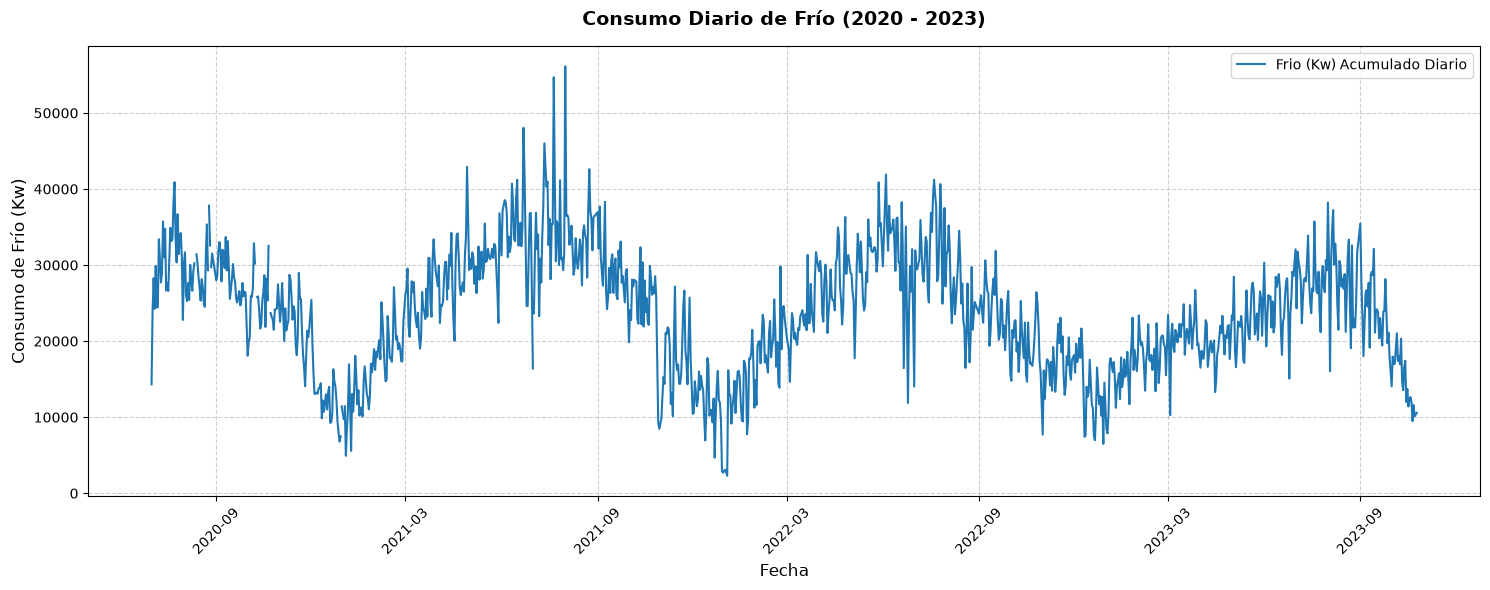

In [69]:


plt.figure(figsize=(15, 6))

# Generar el gráfico de líneas
plt.plot(df['DIA'], df['Frio (Kw) (Consolidado EE)'], 
         color='#1f77b4', linewidth=1.5, label='Frio (Kw) Acumulado Diario')

# Configuración de etiquetas y título
plt.title('Consumo Diario de Frío (2020 - 2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)

# --- NUEVO CÓDIGO PARA EL EJE X ---
ax = plt.gca() # Obtener los ejes actuales

# Mostrar las etiquetas cada 6 meses
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))

# Darle formato a la fecha (por ejemplo: '2020-01' para Año-Mes. Puedes usar '%Y-%m-%d' para día también)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Rotar las fechas 45 grados para que no se superpongan
plt.xticks(rotation=45)
# ----------------------------------

# Formato visual
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Ajustar los márgenes automáticamente para que no se corten las etiquetas
plt.tight_layout()

# Mostrar el gráfico en pantalla
plt.show()

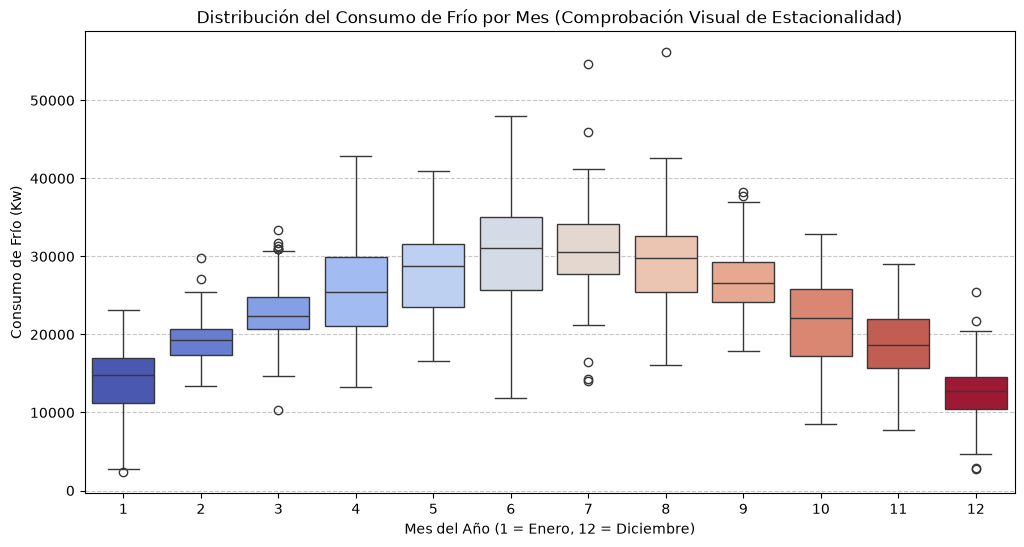

In [70]:
df = df.copy()

# Convertir la fecha y crear las columnas
df['DIA'] = pd.to_datetime(df['DIA'])
df['Mes'] = df['DIA'].dt.month
df['Año'] = df['DIA'].dt.year

plt.figure(figsize=(12, 6))
sns.boxplot(
    x='Mes', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    hue='Mes', 
    palette='coolwarm', 
    legend=False
)

plt.title('Distribución del Consumo de Frío por Mes (Comprobación Visual de Estacionalidad)')
plt.xlabel('Mes del Año (1 = Enero, 12 = Diciembre)')
plt.ylabel('Consumo de Frío (Kw)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

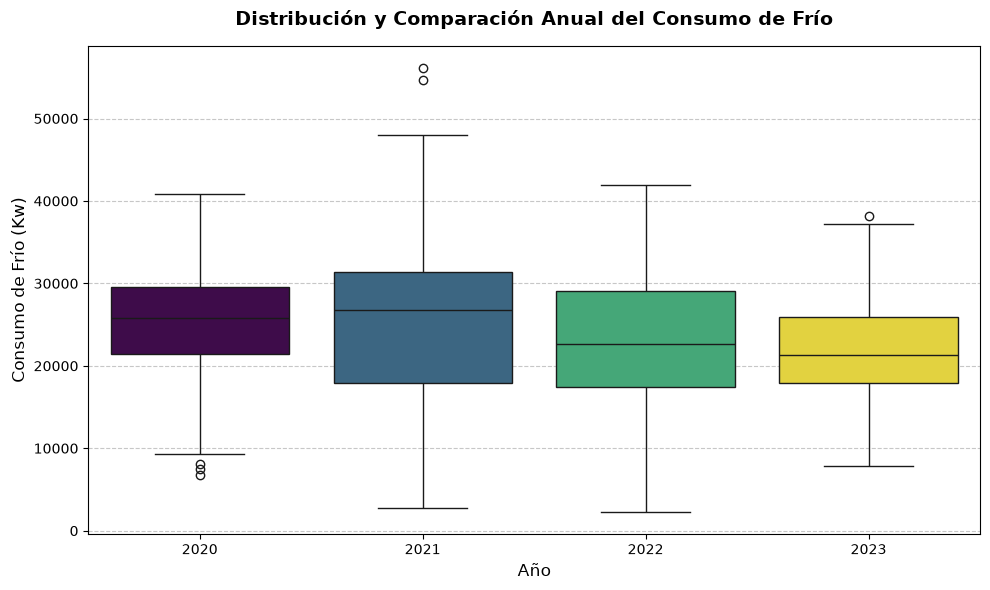

In [71]:
plt.figure(figsize=(10, 6))

# Generar el boxplot por Año
sns.boxplot(
    x='Año', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    hue='Año', 
    palette='viridis', # Paleta de colores distinta para que se vea bien
    legend=False
)

# Configuración de etiquetas y título
plt.title('Distribución y Comparación Anual del Consumo de Frío', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)

# Formato visual
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

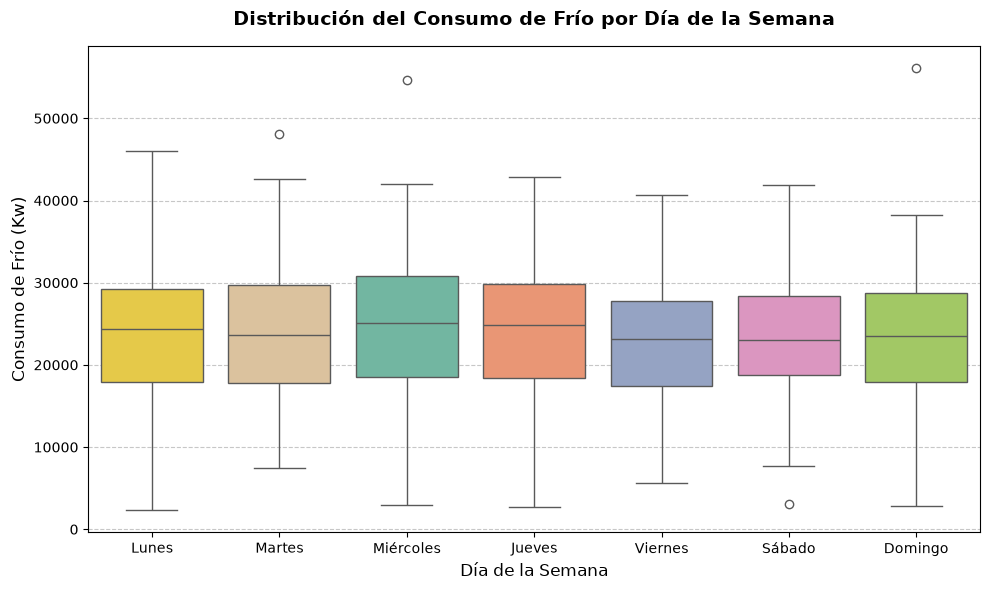

In [72]:
df['Dia_Num'] = df['DIA'].dt.dayofweek

# Mapeamos los números a los nombres de los días
nombres_dias = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
df['Dia_Semana'] = df['Dia_Num'].map(nombres_dias)

# Definimos el orden lógico para que el gráfico empiece el Lunes y termine el Domingo
orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='Dia_Semana', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    order=orden_dias, # Obligamos a que respete el orden de Lunes a Domingo
    hue='Dia_Semana',
    palette='Set2', 
    legend=False
)

plt.title('Distribución del Consumo de Frío por Día de la Semana', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Día de la Semana', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

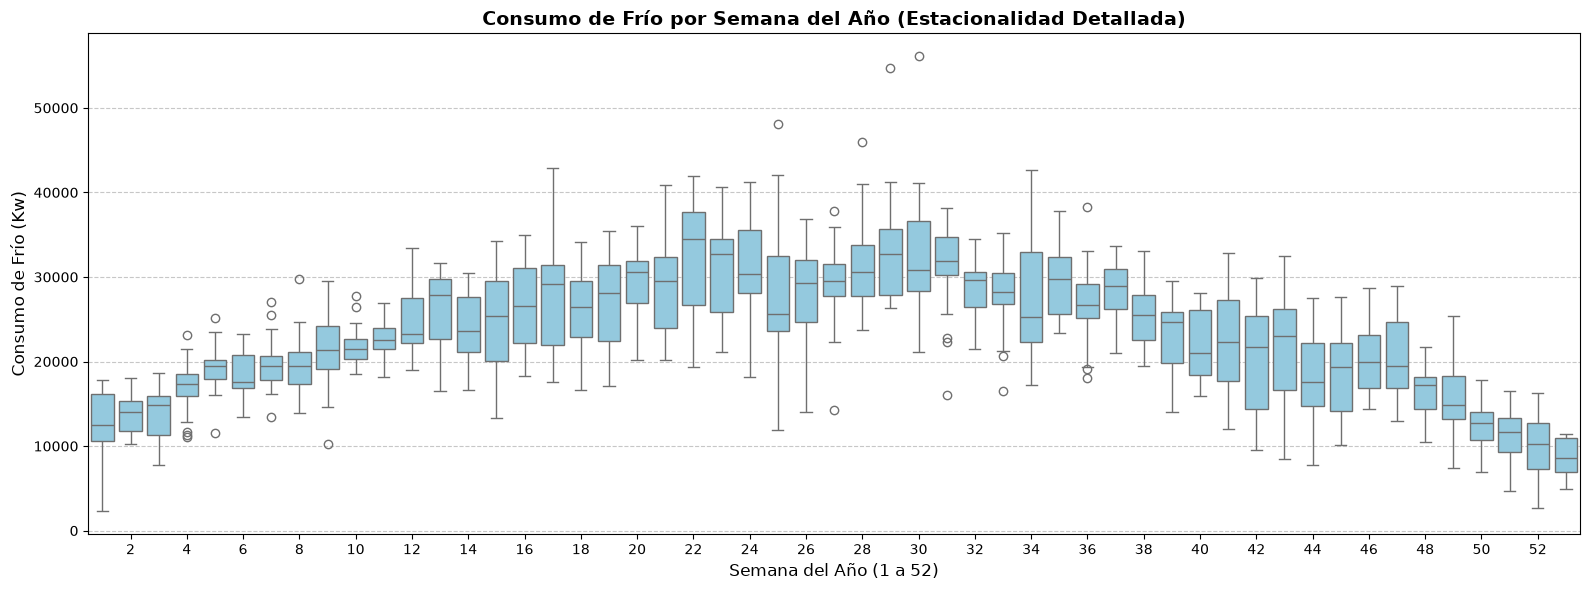

In [73]:
df['Semana_Año'] = df['DIA'].dt.isocalendar().week

plt.figure(figsize=(16, 6))
sns.boxplot(
    x='Semana_Año', 
    y='Frio (Kw) (Consolidado EE)', 
    data=df, 
    color='skyblue'
)

plt.title('Consumo de Frío por Semana del Año (Estacionalidad Detallada)', fontsize=14, fontweight='bold')
plt.xlabel('Semana del Año (1 a 52)', fontsize=12)
plt.ylabel('Consumo de Frío (Kw)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostramos solo semanas pares en el eje X para que no se amontone el texto
plt.xticks(ticks=range(1, 53, 2), labels=range(2, 54, 2))
plt.tight_layout()
plt.show()

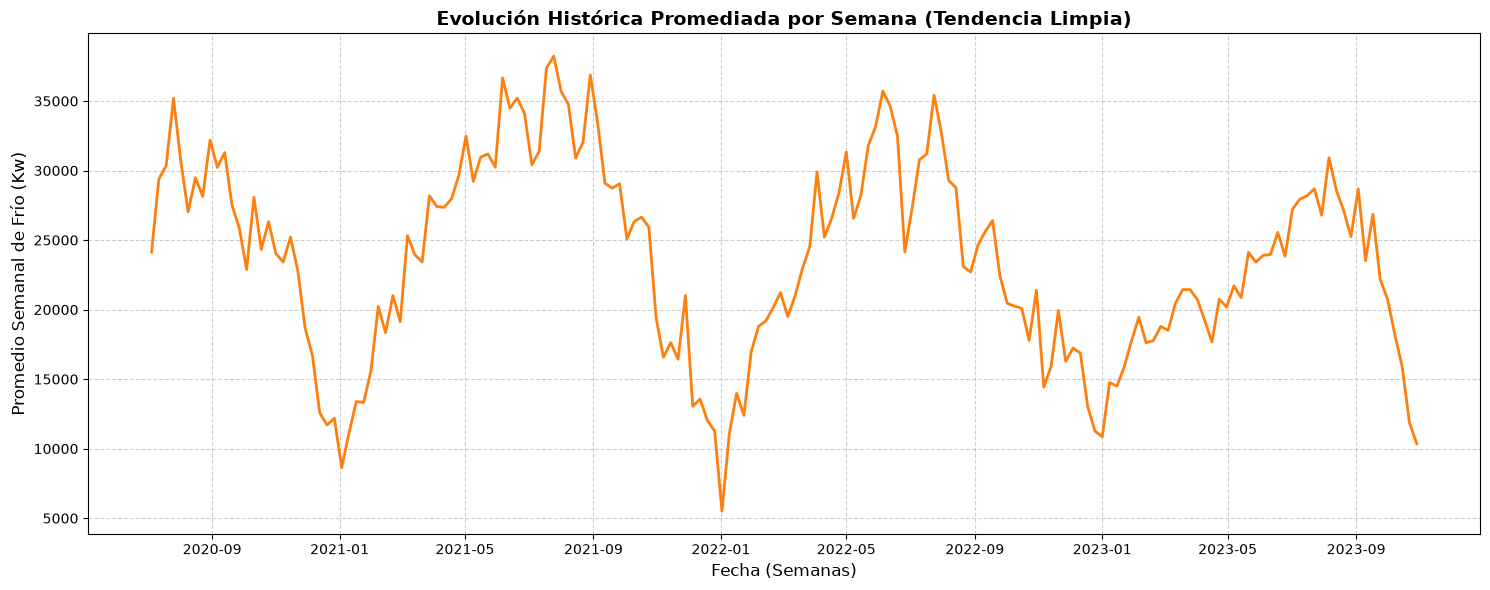

In [74]:
df_temp = df.set_index('DIA')

# Agrupamos por semana ('W') y calculamos el promedio de consumo de esa semana
df_semanal = df_temp['Frio (Kw) (Consolidado EE)'].resample('W').mean()

plt.figure(figsize=(15, 6))
plt.plot(df_semanal.index, df_semanal.values, color='#ff7f0e', linewidth=2)

plt.title('Evolución Histórica Promediada por Semana (Tendencia Limpia)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha (Semanas)', fontsize=12)
plt.ylabel('Promedio Semanal de Frío (Kw)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Las 15 variables más correlacionadas con el Target son:
Target_Frio_Manana                          1.000000
Frio (Kw) (Consolidado EE)                  0.833918
Servicios (Kw) (Consolidado EE)             0.805826
Agua Planta (Hl) (Consolidado Agua)         0.701015
Planta de agua (Hl) (Consolidado Agua)      0.692914
Meta ET Linea 4 (Consolidado KPI)          -0.666580
Meta ET Linea 3 (Consolidado KPI)          -0.666580
Meta ET Servicios (Consolidado KPI)        -0.666580
Meta ET Planta (Consolidado KPI)           -0.666580
Meta ET Elab (Consolidado KPI)             -0.666580
Meta ET Envasado (Consolidado KPI)         -0.666580
Meta ET Cocina (Consolidado KPI)           -0.666580
Meta ET Bodega (Consolidado KPI)           -0.666580
Meta ET Linea 5 (Consolidado KPI)          -0.666580
Meta ET Linea 2 (Consolidado KPI)          -0.666580
KW Cond 5. 6 y 9 (Totalizadores Energia)    0.665931
Name: Target_Frio_Manana, dtype: float64


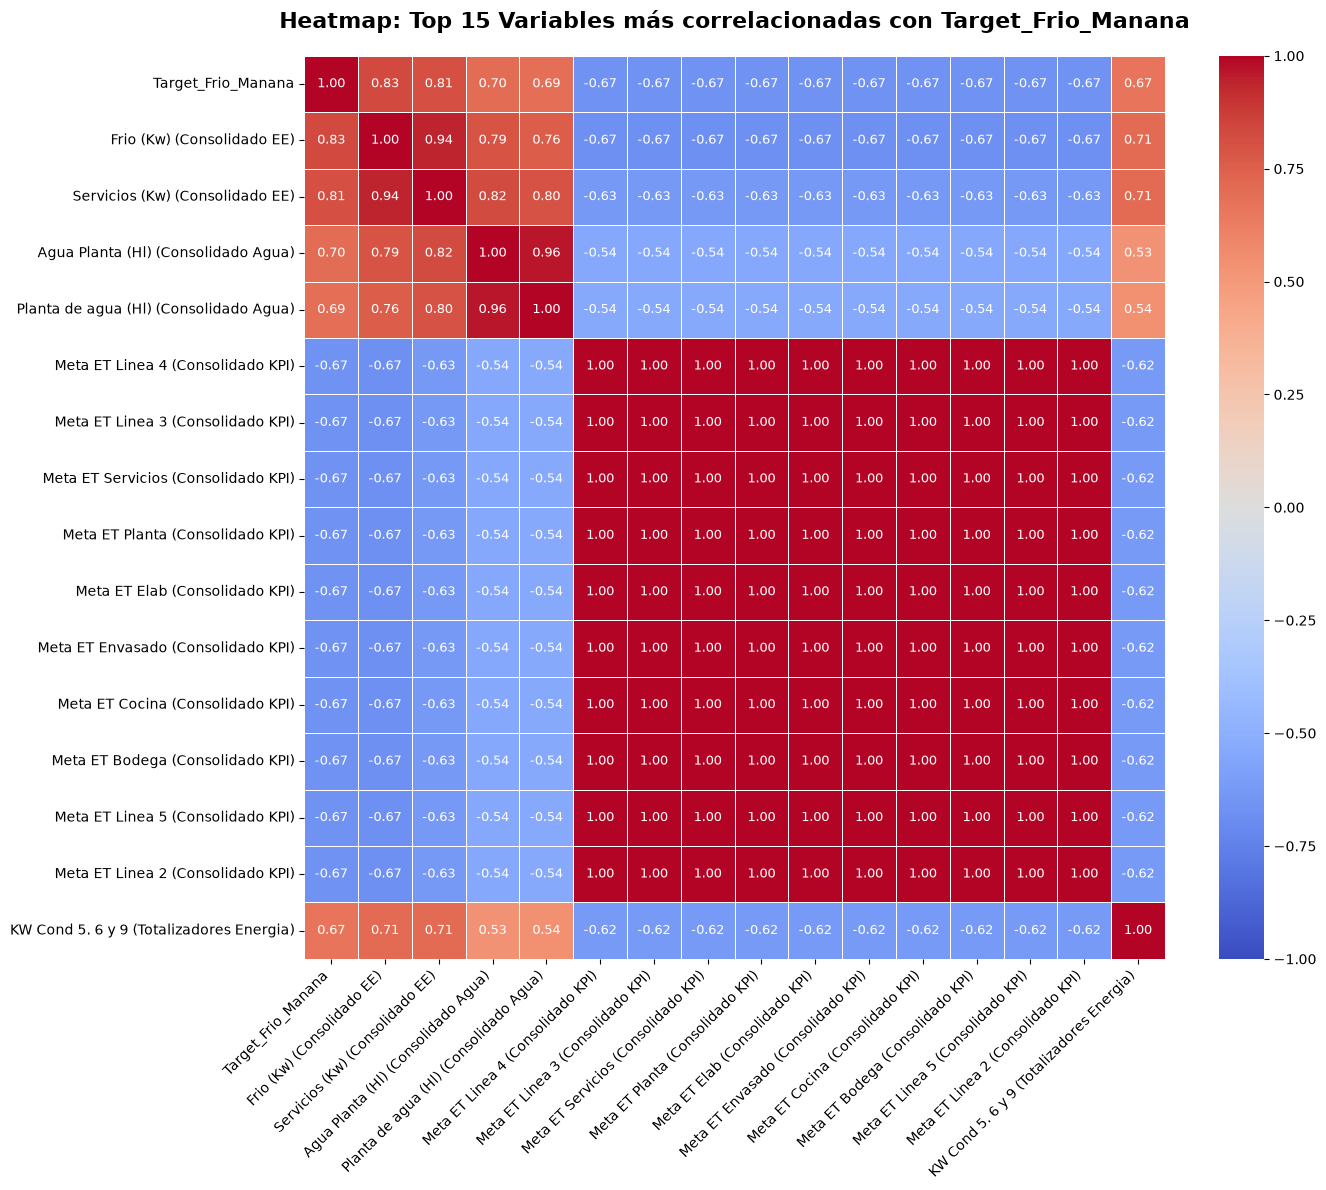

In [75]:
df_numerico = df.select_dtypes(include=['float64', 'int64'])

# 2. Calculamos la matriz de correlación de TODO, pero nos quedamos solo con la columna del Target
# Usamos .abs() para considerar las relaciones negativas y positivas más fuertes por igual
correlaciones_target = df_numerico.corr()['Target_Frio_Manana'].abs().sort_values(ascending=False)

# 3. Obtenemos el nombre de las 15 variables más correlacionadas
# Usamos head(16) porque la primera variable será 'Target_Frio_Manana' (correlación perfecta de 1.0)
top_15_variables = correlaciones_target.head(16).index

# Mostrar en consola cuáles son esas variables y su correlación real (con su signo original)
print("Las 15 variables más correlacionadas con el Target son:")
print(df_numerico.corr()['Target_Frio_Manana'][top_15_variables])

# 4. Filtramos el DataFrame original para quedarnos SOLO con estas 16 variables (Target + 15 features)
df_top_15 = df_numerico[top_15_variables]

# 5. Calculamos la matriz de correlación (16x16)
matriz_top_15 = df_top_15.corr()

# 6. Graficamos el Heatmap
plt.figure(figsize=(14, 12))

# annot_kws={"size": 9} achica un poco el tamaño de los números para que entren bien
sns.heatmap(
    matriz_top_15, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    annot_kws={"size": 9}
)

plt.title('Heatmap: Top 15 Variables más correlacionadas con Target_Frio_Manana', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [76]:
predictores = top_15_variables.drop('Target_Frio_Manana')
X = df_top_15[predictores].dropna() # VIF y las matrices fallan si hay valores nulos (NaN)

print("--- 1. PARES CON ALTA CORRELACIÓN (> 0.80) ---")
# Calculamos la matriz de correlación solo entre los predictores
matriz_predictores = X.corr().abs()

# Extraemos el triángulo superior de la matriz para no tener duplicados
upper_tri = matriz_predictores.where(np.triu(np.ones(matriz_predictores.shape), k=1).astype(bool))

# Buscamos pares con correlación mayor a 0.80 (umbral de alerta de multicolinealidad)
pares_altos = [
    (columna, indice, upper_tri[columna][indice]) 
    for columna in upper_tri.columns 
    for indice in upper_tri.index 
    if upper_tri[columna][indice] > 0.80
]

if pares_altos:
    for col, idx, val in pares_altos:
        print(f"Alerta: '{col}' y '{idx}' tienen una correlación de {val:.2f}")
else:
    print("No se encontraron pares con correlación > 0.80")

print("\n--- 2. FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ---")
# Para que statsmodels calcule el VIF correctamente, debemos agregar una constante (intercepto)
X_con_constante = sm.add_constant(X)

# Calculamos el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X_con_constante.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_con_constante.values, i) 
    for i in range(X_con_constante.shape[1])
]

# Filtramos la constante para mostrar solo nuestras variables y ordenamos
vif_data = vif_data[vif_data['Variable'] != 'const'].sort_values(by='VIF', ascending=False)
print(vif_data.to_string(index=False))

--- 1. PARES CON ALTA CORRELACIÓN (> 0.80) ---
Alerta: 'Servicios (Kw) (Consolidado EE)' y 'Frio (Kw) (Consolidado EE)' tienen una correlación de 0.93
Alerta: 'Agua Planta (Hl) (Consolidado Agua)' y 'Servicios (Kw) (Consolidado EE)' tienen una correlación de 0.82
Alerta: 'Planta de agua (Hl) (Consolidado Agua)' y 'Servicios (Kw) (Consolidado EE)' tienen una correlación de 0.80
Alerta: 'Planta de agua (Hl) (Consolidado Agua)' y 'Agua Planta (Hl) (Consolidado Agua)' tienen una correlación de 0.96
Alerta: 'Meta ET Linea 3 (Consolidado KPI)' y 'Meta ET Linea 4 (Consolidado KPI)' tienen una correlación de 1.00
Alerta: 'Meta ET Servicios (Consolidado KPI)' y 'Meta ET Linea 4 (Consolidado KPI)' tienen una correlación de 1.00
Alerta: 'Meta ET Servicios (Consolidado KPI)' y 'Meta ET Linea 3 (Consolidado KPI)' tienen una correlación de 1.00
Alerta: 'Meta ET Planta (Consolidado KPI)' y 'Meta ET Linea 4 (Consolidado KPI)' tienen una correlación de 1.00
Alerta: 'Meta ET Planta (Consolidado KPI)' y 

C:\Users\geron\AppData\Local\Temp\ipykernel_9728\4200815815.py:33: UserWarning: The design matrix is poorly conditioned (condition number=1.01e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_con_constante.values, i)
c:\Users\geron\anaconda3\envs\cervecera_env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\geron\anaconda3\envs\cervecera_env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\geron\anaconda3\envs\cervecera_env\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i,

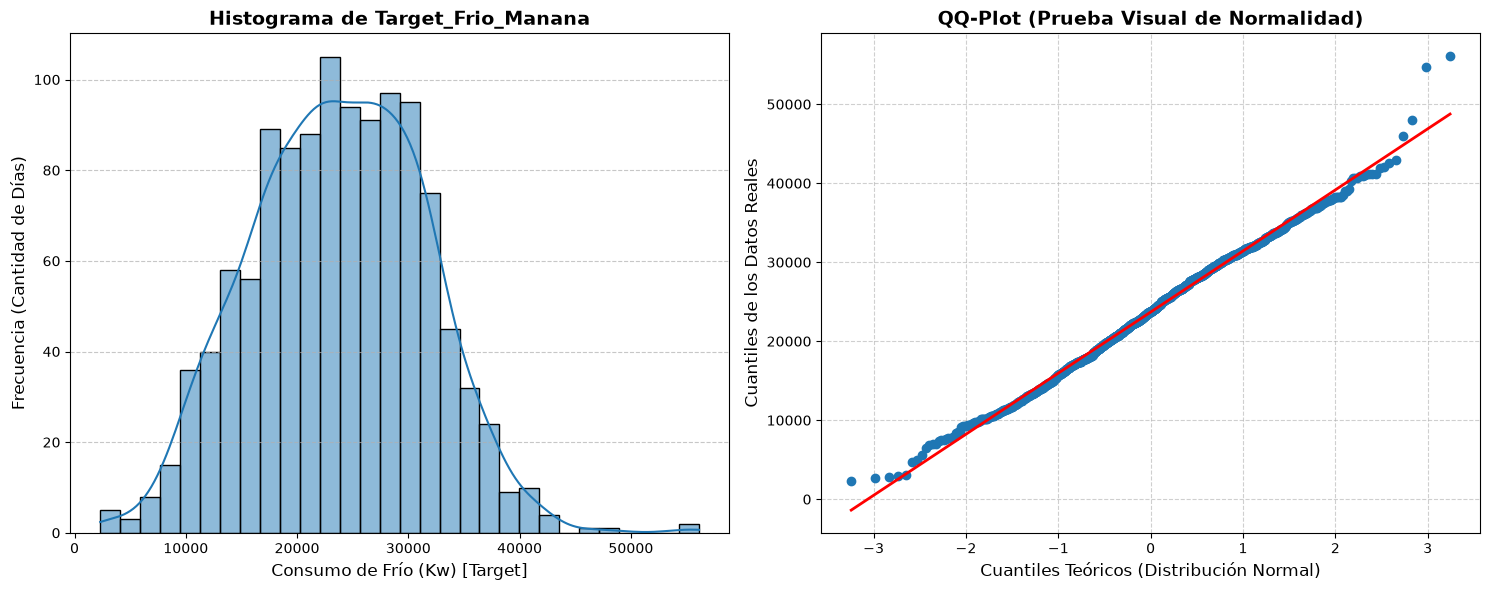

In [77]:
target = df['Target_Frio_Manana'].dropna()

# Crear un lienzo con 2 subgráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# ---------------------------------------------------------
# 1. HISTOGRAMA CON CURVA DE DENSIDAD (KDE)
# ---------------------------------------------------------
sns.histplot(target, kde=True, color='#1f77b4', ax=ax1, bins=30)
ax1.set_title('Histograma de Target_Frio_Manana', fontsize=14, fontweight='bold')
ax1.set_xlabel('Consumo de Frío (Kw) [Target]', fontsize=12)
ax1.set_ylabel('Frecuencia (Cantidad de Días)', fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# ---------------------------------------------------------
# 2. QQ-PLOT (Gráfico Cuantil-Cuantil)
# ---------------------------------------------------------
# stats.probplot compara nuestra variable contra una distribución normal teórica ("norm")
stats.probplot(target, dist="norm", plot=ax2)

# Personalización de colores del QQ-Plot para que coincida con el estilo
ax2.get_lines()[0].set_markerfacecolor('#1f77b4') # Puntos azules
ax2.get_lines()[0].set_markeredgecolor('#1f77b4') 
ax2.get_lines()[1].set_color('red')               # Línea de referencia roja
ax2.get_lines()[1].set_linewidth(2)

ax2.set_title('QQ-Plot (Prueba Visual de Normalidad)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Cuantiles Teóricos (Distribución Normal)', fontsize=12)
ax2.set_ylabel('Cuantiles de los Datos Reales', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# Ajustar márgenes y mostrar
plt.tight_layout()
plt.show()

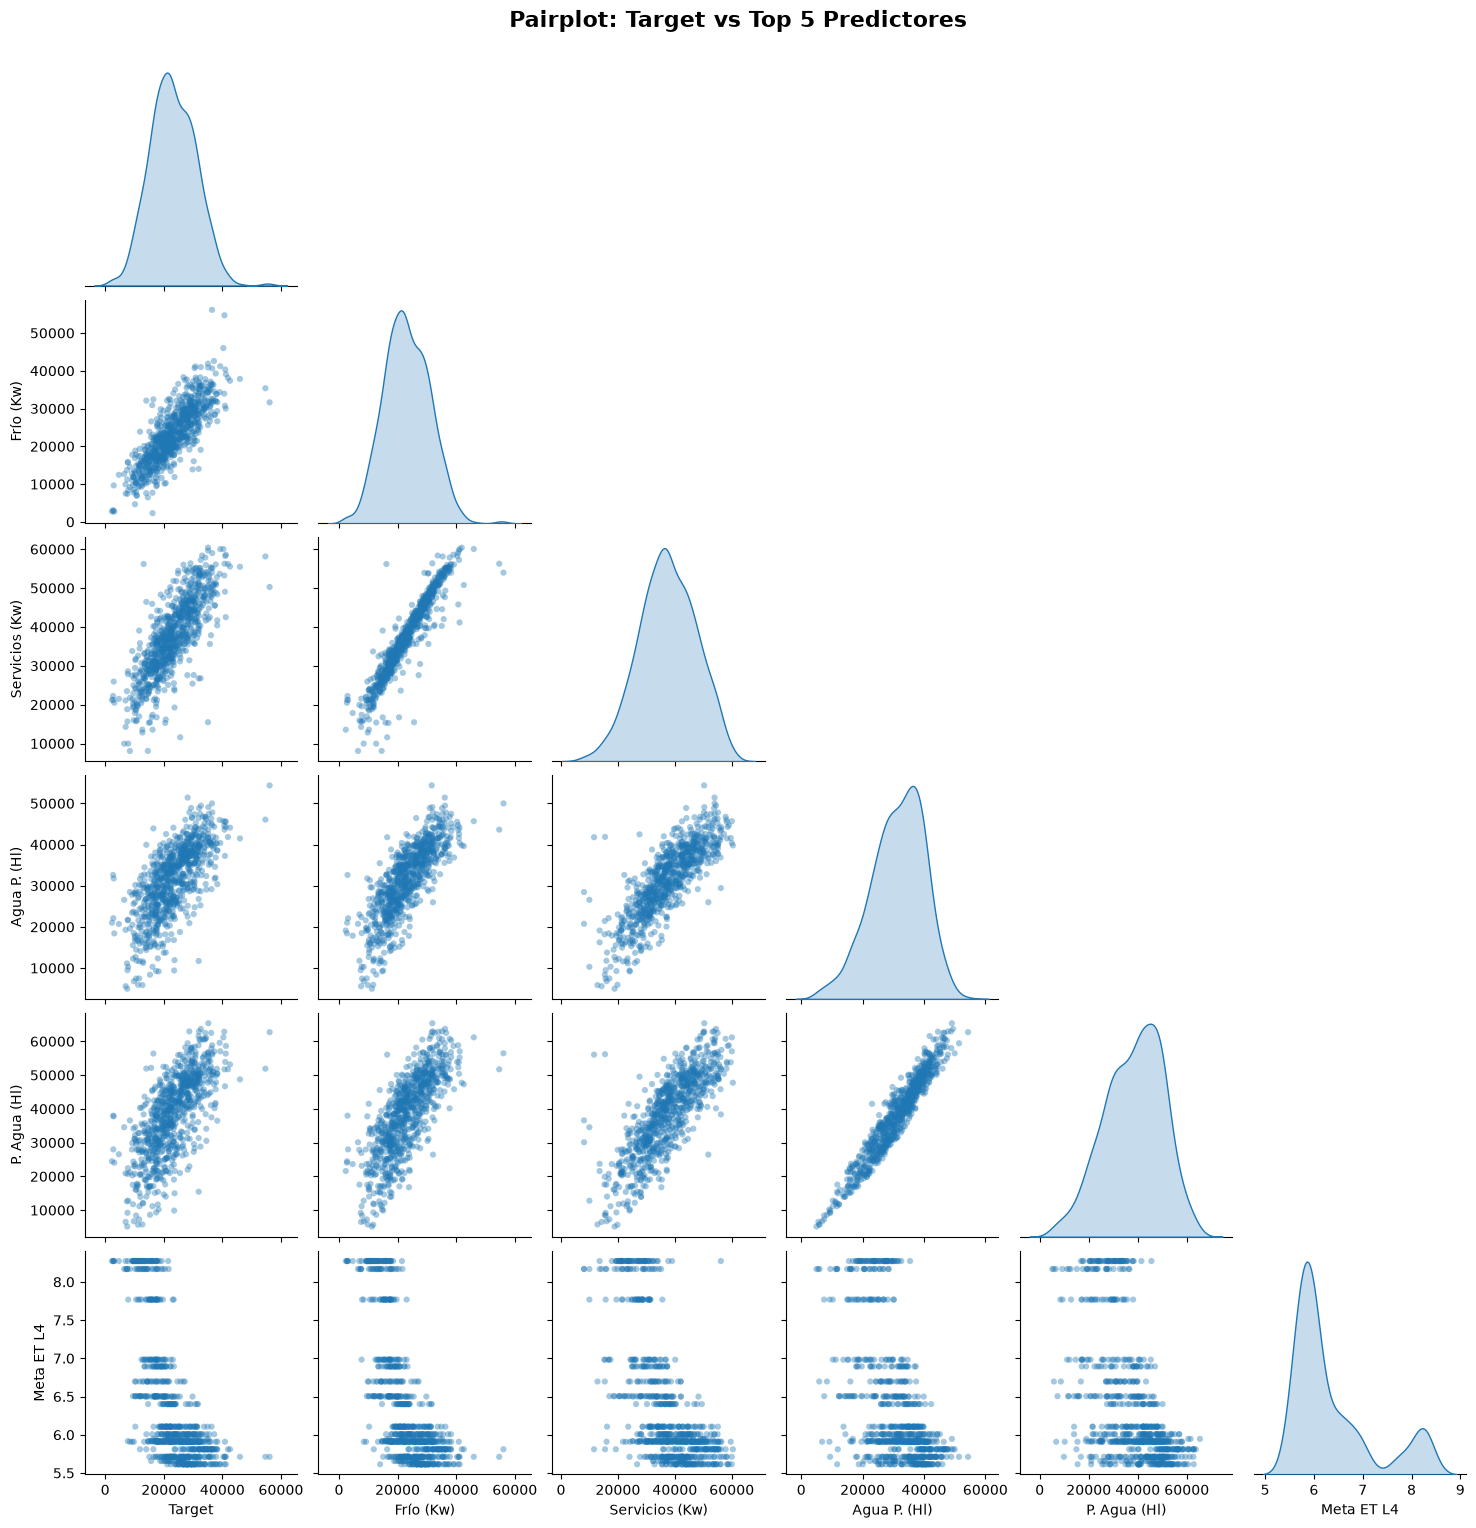

In [78]:
columnas_pairplot = [
    'Target_Frio_Manana',
    'Frio (Kw) (Consolidado EE)', 
    'Servicios (Kw) (Consolidado EE)', 
    'Agua Planta (Hl) (Consolidado Agua)', 
    'Planta de agua (Hl) (Consolidado Agua)', 
    'Meta ET Linea 4 (Consolidado KPI)'
]

# 2. Filtramos el DataFrame original sin nulos
df_pairplot = df[columnas_pairplot].dropna()

# 3. CREAMOS UN DICCIONARIO CON NOMBRES MÁS CORTOS
nombres_cortos = {
    'Target_Frio_Manana': 'Target',
    'Frio (Kw) (Consolidado EE)': 'Frío (Kw)', 
    'Servicios (Kw) (Consolidado EE)': 'Servicios (Kw)', 
    'Agua Planta (Hl) (Consolidado Agua)': 'Agua P. (Hl)', 
    'Planta de agua (Hl) (Consolidado Agua)': 'P. Agua (Hl)', 
    'Meta ET Linea 4 (Consolidado KPI)': 'Meta ET L4'
}

# 4. Renombramos las columnas en nuestro DataFrame temporal
df_pairplot = df_pairplot.rename(columns=nombres_cortos)

# 5. Generamos el Pairplot
g = sns.pairplot(
    df_pairplot, 
    diag_kind='kde', 
    corner=True,
    plot_kws={'alpha': 0.4, 's': 20, 'edgecolor': 'none'}
)

g.fig.suptitle('Pairplot: Target vs Top 5 Predictores', y=1.02, fontsize=16, fontweight='bold')
plt.show()

In [79]:
palabras_clave = 'Planta|Produccion|Bodega|Cocina|Elaboracion'


columnas_encontradas = df.columns[df.columns.str.contains(palabras_clave, case=False, na=False)].tolist()

print(f"Se encontraron {len(columnas_encontradas)} columnas:")
for col in columnas_encontradas:
    print("-", col)

palabras_clave_completas = 'DIA|Target_Frio_Manana|Planta|Produccion|Bodega|Cocina|Elaboracion'

df_areas_y_target = df.filter(regex=f'(?i){palabras_clave_completas}')

Se encontraron 132 columnas:
- EE Planta / Hl (Consolidado KPI)
- EE Elaboracion / Hl (Consolidado KPI)
- EE Bodega / Hl (Consolidado KPI)
- EE Cocina / Hl (Consolidado KPI)
- EE Resto Planta / Hl (Consolidado KPI)
- Agua Planta / Hl (Consolidado KPI)
- Agua Bodega / Hl (Consolidado KPI)
- Agua Cocina / Hl (Consolidado KPI)
- Agua Planta de Agua/Hl (Consolidado KPI)
- Produccion Agua / Hl (Consolidado KPI)
- ET Planta / Hl (Consolidado KPI)
- ET Bodega/Hl (Consolidado KPI)
- ET Cocina/Hl (Consolidado KPI)
- Aire Planta / Hl (Consolidado KPI)
- Aire Elaboracion / Hl (Consolidado KPI)
- Aire Cocina / Hl (Consolidado KPI)
- Aire Bodega / Hl (Consolidado KPI)
- Meta EE Planta (Consolidado KPI)
- Meta Agua Planta (Consolidado KPI)
- Meta ET Planta (Consolidado KPI)
- Meta Aire Planta (Consolidado KPI)
- Meta Agua Bodega (Consolidado KPI)
- Meta Agua Cocina (Consolidado KPI)
- Meta Agua Planta de Agua (Consolidado KPI)
- Meta Produccion Agua (Consolidado KPI)
- Meta EE Elaboracion (Consolida

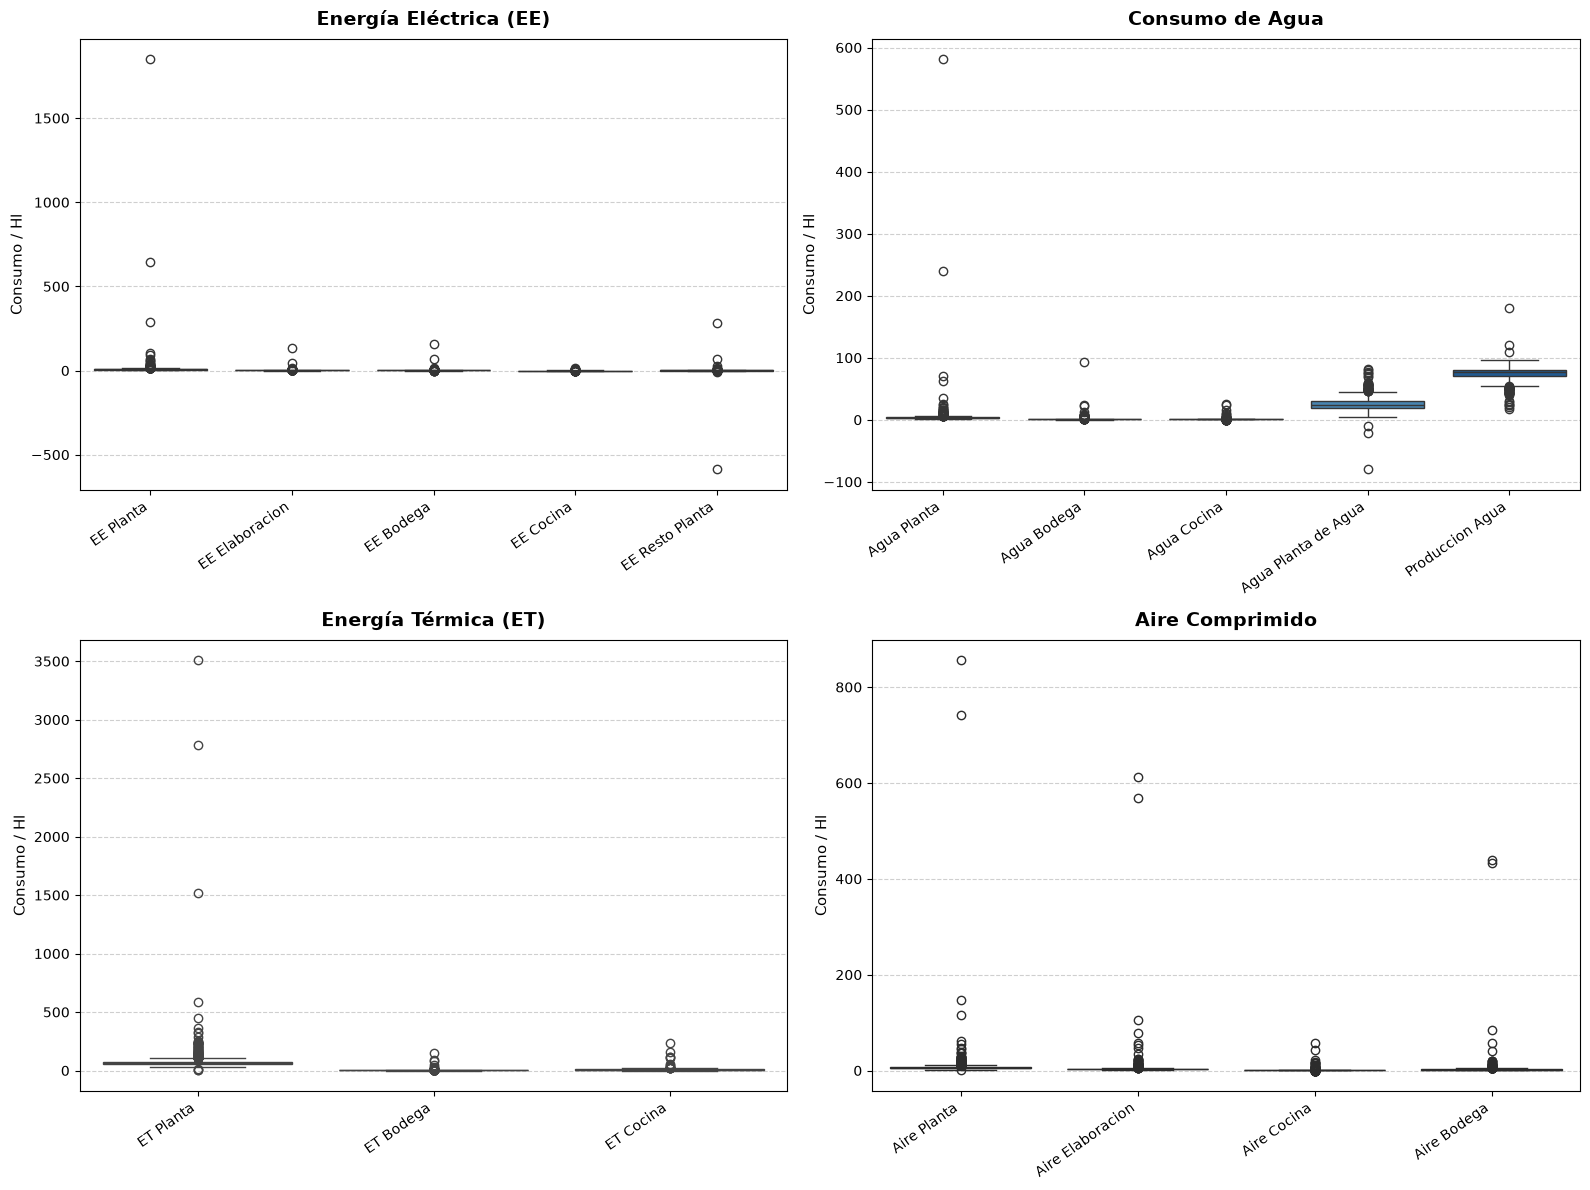

In [80]:
cols_ee = [
    'EE Planta / Hl (Consolidado KPI)',
    'EE Elaboracion / Hl (Consolidado KPI)',
    'EE Bodega / Hl (Consolidado KPI)',
    'EE Cocina / Hl (Consolidado KPI)',
    'EE Resto Planta / Hl (Consolidado KPI)'
]

cols_agua = [
    'Agua Planta / Hl (Consolidado KPI)',
    'Agua Bodega / Hl (Consolidado KPI)',
    'Agua Cocina / Hl (Consolidado KPI)',
    'Agua Planta de Agua/Hl (Consolidado KPI)',
    'Produccion Agua / Hl (Consolidado KPI)'
]

cols_et = [
    'ET Planta / Hl (Consolidado KPI)',
    'ET Bodega/Hl (Consolidado KPI)',
    'ET Cocina/Hl (Consolidado KPI)'
]

cols_aire = [
    'Aire Planta / Hl (Consolidado KPI)',
    'Aire Elaboracion / Hl (Consolidado KPI)',
    'Aire Cocina / Hl (Consolidado KPI)',
    'Aire Bodega / Hl (Consolidado KPI)'
]

# 2. Creamos un lienzo grande con 4 subgráficos (2 filas y 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 3. Agrupamos la información para iterar y graficar fácilmente
categorias = [
    ('Energía Eléctrica (EE)', cols_ee, axes[0, 0], 'YlOrBr'), # Amarillo/Naranja
    ('Consumo de Agua', cols_agua, axes[0, 1], 'Blues'),       # Azul
    ('Energía Térmica (ET)', cols_et, axes[1, 0], 'Reds'),     # Rojo
    ('Aire Comprimido', cols_aire, axes[1, 1], 'Greens')       # Verde
]

# 4. Generamos cada uno de los 4 gráficos
for titulo, columnas, ax, paleta in categorias:
    
    # Graficar usando solo las columnas correspondientes
    sns.boxplot(data=df[columnas], ax=ax, palette=paleta)
    
    # Configuración de títulos
    ax.set_title(titulo, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel('Consumo / Hl', fontsize=11)
    
    # Magia para acortar los nombres largos del Eje X: 
    # Nos quedamos solo con la parte antes de la barra "/"
    nombres_cortos = [col.split(' /')[0].split('/')[0] for col in columnas]
    
    ax.set_xticks(range(len(columnas)))
    ax.set_xticklabels(nombres_cortos, rotation=35, ha='right', fontsize=10)
    
    # Grilla de fondo para facilitar la lectura
    ax.grid(axis='y', linestyle='--', alpha=0.6)

# 5. Ajustar márgenes para que nada se superponga y mostrar
plt.tight_layout()
plt.show()